# The Impact of Global Warming on Salmon Runs

Import libraries:

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

Load clean dataset:

In [3]:
df = pd.read_csv(r'C:\Users\portl\OneDrive\Documents\Data Science Certificate\DATA 5100 FQ\Projects\Salmon\data\water_salmon_clean.csv')

In [4]:
df

,Year,temperature,Species,Spawners,Harvest,Harvest Rate,Returns
0,2011-01-01,5.567316,Chinook,47008,23489,0.333191,70497
1,2011-01-01,5.567316,Chum,205566,120434,0.369429,326000
2,2012-01-01,4.918484,Chinook,32328,19121,0.371650,51449
3,2012-01-01,4.918484,Chum,137662,100338,0.421588,238000
4,2013-01-01,5.770873,Chinook,28488,11129,0.280915,39617
5,2013-01-01,5.770873,Chum,200262,102738,0.339069,303000
6,2014-01-01,5.120191,Chinook,63370,1741,0.026739,65111
7,2014-01-01,5.120191,Chum,156796,66204,0.296879,223000
8,2015-01-01,5.281110,Chinook,82695,5646,0.063911,88341
9,2015-01-01,5.281110,Chum,108658,96342,0.469961,205000


In [10]:
df_temp = df[['Year', 'temperature']].iloc[0::2]

In [11]:
df_temp

,Year,temperature
0,2011-01-01,5.567316
2,2012-01-01,4.918484
4,2013-01-01,5.770873
6,2014-01-01,5.120191
8,2015-01-01,5.281110
10,2016-01-01,5.729688
12,2017-01-01,5.388590
14,2018-01-01,4.845551
16,2019-01-01,5.848474
18,2020-01-01,4.950968


Temperature over time graph:

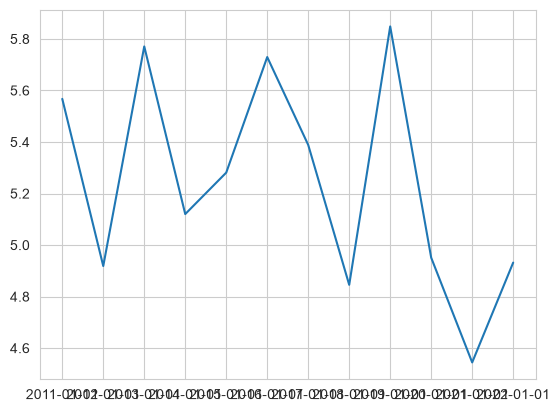

In [17]:
temp_fig= plt.plot(df['Year'].iloc[0::2], df['temperature'].iloc[0::2])

Spawners per year:

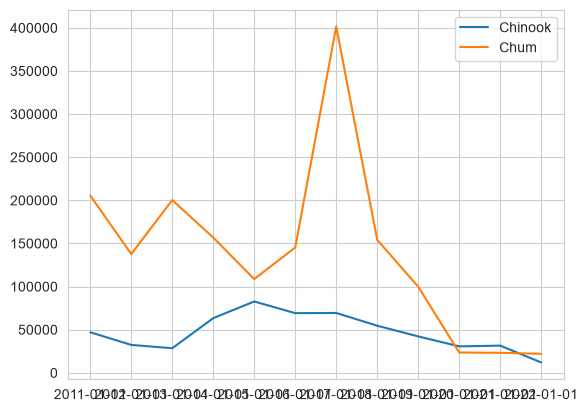

In [22]:
plt.plot(df['Year'].iloc[0::2], df['Spawners'].iloc[0::2], label = 'Chinook')
plt.plot(df['Year'].iloc[1::2], df['Spawners'].iloc[1::2], label = 'Chum')
plt.legend()

Salmon harvested per year:

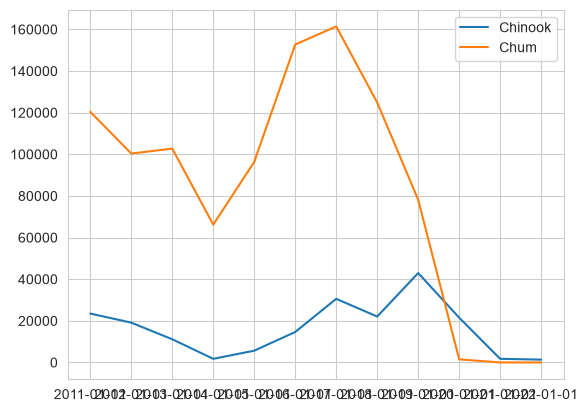

In [23]:
plt.plot(df['Year'].iloc[0::2], df['Harvest'].iloc[0::2], label = 'Chinook')
plt.plot(df['Year'].iloc[1::2], df['Harvest'].iloc[1::2], label = 'Chum')
plt.legend()

Salmon returned per year:

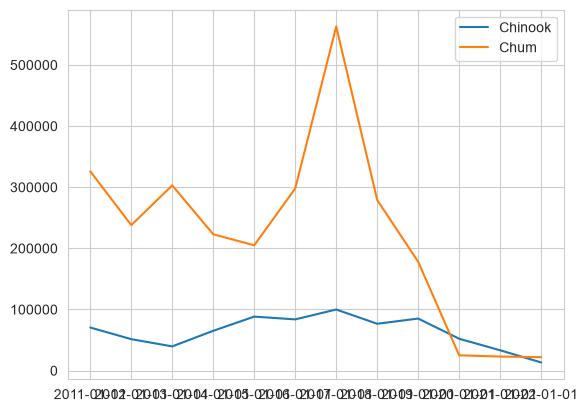

In [24]:
plt.plot(df['Year'].iloc[0::2], df['Returns'].iloc[0::2], label = 'Chinook')
plt.plot(df['Year'].iloc[1::2], df['Returns'].iloc[1::2], label = 'Chum')
plt.legend()

Pair plots:

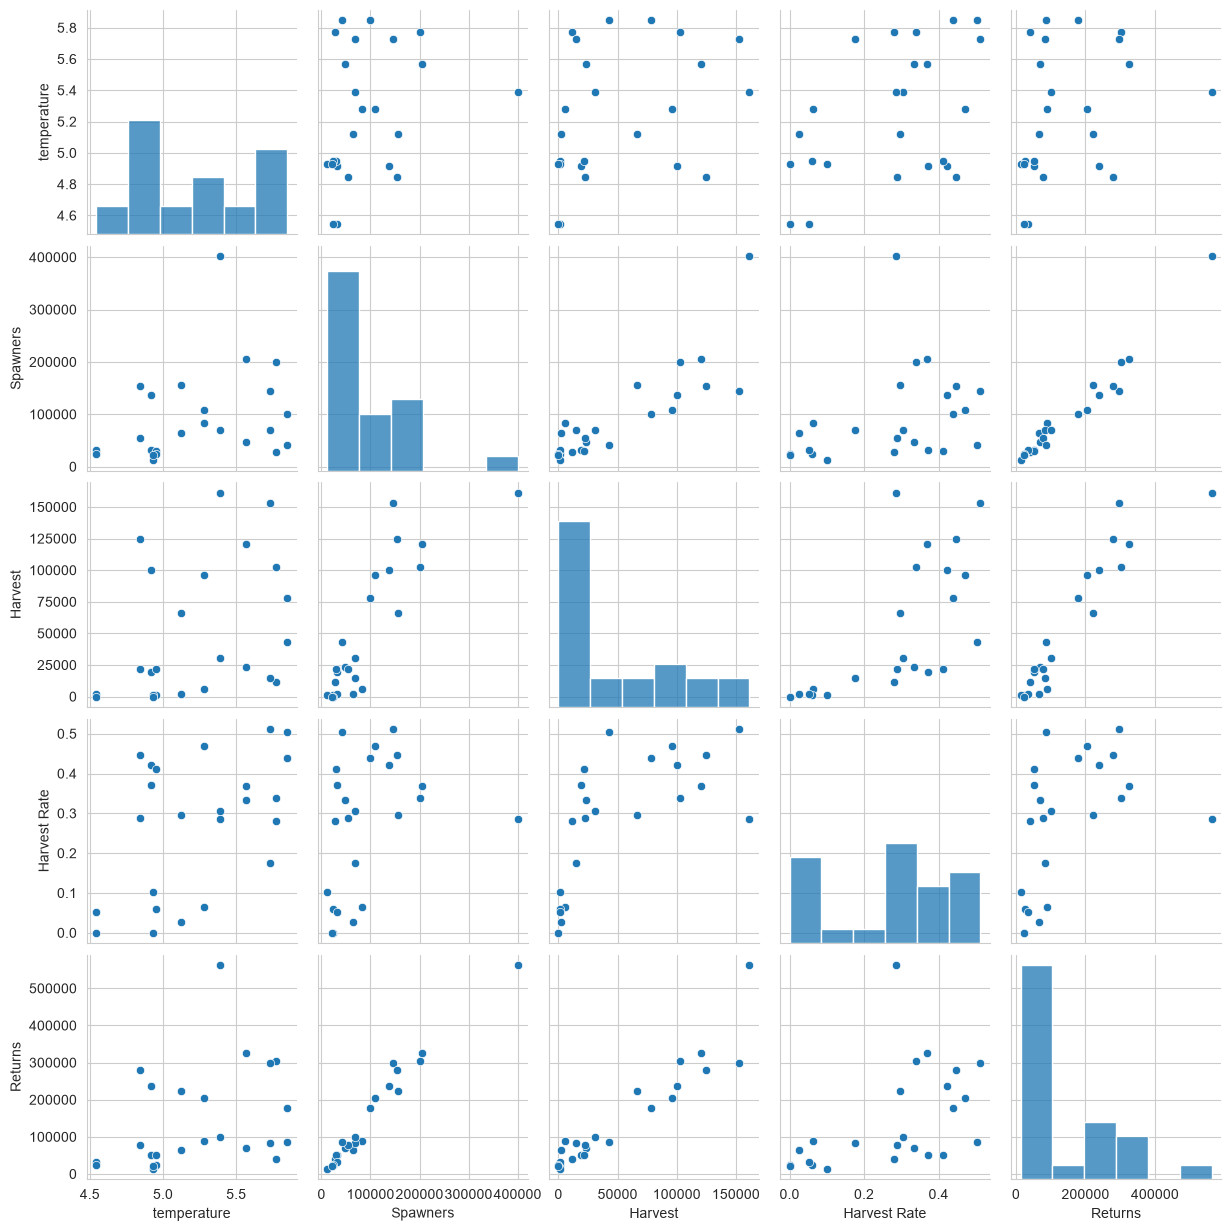

In [27]:
sns.pairplot(df.drop(columns = 'Year'))
plt.show()

OLS model measuring effect of temperature on harvested salmon:

In [29]:
import statsmodels.formula.api as smf
import statsmodels.api as sm

In [30]:
model_temp_harvest = smf.ols(formula = 'Harvest ~ temperature', data = df).fit()

In [31]:
print(model_temp_harvest.summary())

                            OLS Regression Results                            
Dep. Variable:                Harvest   R-squared:                       0.130
Model:                            OLS   Adj. R-squared:                  0.090
Method:                 Least Squares   F-statistic:                     3.275
Date:                Fri, 30 Oct 2026   Prob (F-statistic):             0.0840
Time:                        12:09:02   Log-Likelihood:                -292.99
No. Observations:                  24   AIC:                             590.0
Df Residuals:                      22   BIC:                             592.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept   -1.927e+05   1.35e+05     -1.433      

p-values and r-squared values are both low